In [1]:
import sys
from pathlib import Path
import soundfile as sf
import IPython
import numpy as np
import matplotlib.pyplot as plt
import sklearn

# make src/ importable
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import features

DATA = ROOT / "data" / "gtzan"

In [2]:
# sorted so the label order is stable
genre_names = sorted(p.name for p in (DATA / "genres").iterdir() if p.is_dir())

# play 5 s of one clip per genre
for genre in genre_names:

    x, fs = sf.read(DATA / "genres" / genre / f"{genre}.00000.wav", frames=5 * 22050)

    print(genre)
    IPython.display.display(IPython.display.Audio(data=x, rate=fs))

blues


classical


country


disco


hiphop


jazz


metal


pop


reggae


rock


In [3]:
valid_files = {"train": [], "valid": [], "test": []}

for split in valid_files:

    file_list = (DATA / "splits" / f"{split}_filtered.txt").read_text().split()

    for f in file_list:

        try:
            # header only, no decoding
            info = sf.info(DATA / "genres" / f)

            if info.duration < 29 or info.duration > 31:

                print(f"Wrong duration ({info.duration:.2f} s): {f}")
                continue

            valid_files[split].append(f)

        except sf.LibsndfileError:
            print(f"Could not read corrupted file: {f}")

for split, files in valid_files.items():
    print(f"{split}: {len(files)} valid files")

Could not read corrupted file: jazz/jazz.00054.wav
train: 442 valid files
valid: 197 valid files
test: 290 valid files


In [4]:
# sanity check on one clip
example = features.extract(DATA / "genres" / valid_files["train"][0])

names = example["names"]

# the three features from feat_ext
for feat in ["zcr_mean", "centroid_mean", "rms_mean"]:
    print(f"{feat}: {example['summary'][names.index(feat)]:.4f}")

print("summary vector shape:", example["summary"].shape)

/Users/emredayangac/Documents/UoE/courses/audio-ml/graded/two/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


zcr_mean: 0.0529
centroid_mean: 1649.2096
rms_mean: 0.1247
summary vector shape: (145,)


In [5]:
label_map = {genre: i for i, genre in enumerate(genre_names)}

print(label_map)

# cached by scripts/extract.py
cached = {split: np.load(DATA / "features" / f"{split}.npz") for split in ["train", "valid", "test"]}

# cache must match the files that passed the checks
for split, d in cached.items():
    assert list(d["paths"]) == valid_files[split], f"cache out of date for {split}"
    assert [str(g) for g in d["genres"]] == genre_names

X_train, y_train = cached["train"]["summary"], cached["train"]["labels"]
X_val, y_val = cached["valid"]["summary"], cached["valid"]["labels"]
X_test, y_test = cached["test"]["summary"], cached["test"]["labels"]

feature_names = [str(n) for n in cached["train"]["names"]]

for split, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    assert np.isfinite(X).all()
    print(f"{split}: X {X.shape}, y {y.shape}, per class {np.bincount(y)}")

{'blues': 0, 'classical': 1, 'country': 2, 'disco': 3, 'hiphop': 4, 'jazz': 5, 'metal': 6, 'pop': 7, 'reggae': 8, 'rock': 9}
train: X (442, 145), y (442,), per class [46 48 45 42 47 42 44 41 43 44]
val: X (197, 145), y (197,), per class [23 20 23 22 18 17 20 13 17 24]
test: X (290, 145), y (290,), per class [31 31 30 29 27 27 27 30 26 32]


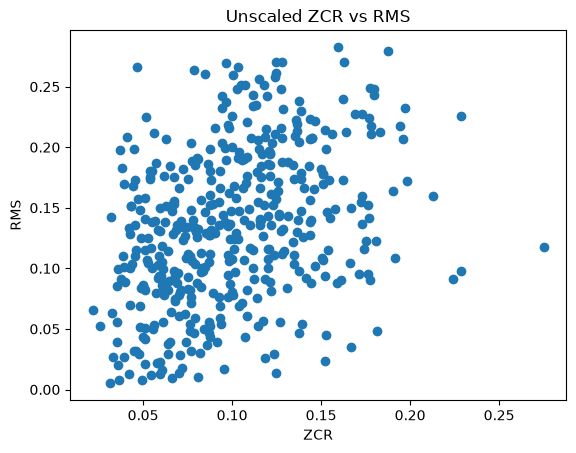

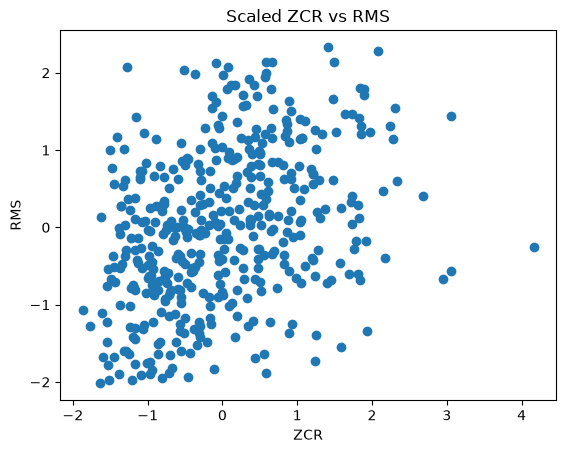

In [6]:
# fixed artist-filtered split, so no train_test_split

# scaler fit on train only
scaler = sklearn.preprocessing.StandardScaler()
scaler.fit(X_train)

X_train_sc = scaler.transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)

zcr_col = feature_names.index("zcr_mean")
rms_col = feature_names.index("rms_mean")

plt.title("Unscaled ZCR vs RMS")
plt.xlabel("ZCR")
plt.ylabel("RMS")
plt.scatter(X_train[:, zcr_col], X_train[:, rms_col])
plt.show()

plt.title("Scaled ZCR vs RMS")
plt.xlabel("ZCR")
plt.ylabel("RMS")
plt.scatter(X_train_sc[:, zcr_col], X_train_sc[:, rms_col])
plt.show()

In [7]:
# higher max_iter so it converges
logreg = sklearn.linear_model.LogisticRegression(max_iter=5000)

logreg.fit(X_train_sc, y_train)

logreg_predictions = logreg.predict(X_val_sc)

logreg_accuracy = sklearn.metrics.accuracy_score(y_val, logreg_predictions)
print(f"Logistic Regression Val Accuracy: {logreg_accuracy:.4f}")

logreg_predictions_train = logreg.predict(X_train_sc)
logreg_accuracy_train = sklearn.metrics.accuracy_score(y_train, logreg_predictions_train)
print(f"Logistic Regression Train Accuracy: {logreg_accuracy_train:.4f}")
print("\n")

# 21 and 31 added: ~3x more clips per class than in assessment 1
k_list = [1, 3, 5, 9, 15, 21, 31]

best_k = 0
best_val_accuracy = 0
best_knn = None

val_accuracies = []
train_accuracies = []

for k in k_list:

    kNearest = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k)

    kNearest.fit(X_train_sc, y_train)

    kNearest_predictions = kNearest.predict(X_val_sc)

    kNearest_accuracy = sklearn.metrics.accuracy_score(y_val, kNearest_predictions)

    kNearest_predictions_train = kNearest.predict(X_train_sc)
    kNearest_accuracy_train = sklearn.metrics.accuracy_score(y_train, kNearest_predictions_train)

    val_accuracies.append(kNearest_accuracy)
    train_accuracies.append(kNearest_accuracy_train)

    print(f"k = {k:2d}  Val Accuracy: {kNearest_accuracy:.4f}  Train Accuracy: {kNearest_accuracy_train:.4f}")

    if kNearest_accuracy >= best_val_accuracy:

        best_k = k
        best_val_accuracy = kNearest_accuracy
        best_knn = kNearest

print(f"\nbest kNN was k equal to {best_k} with Val Accuracy {best_val_accuracy:.4f}")

Logistic Regression Val Accuracy: 0.5584
Logistic Regression Train Accuracy: 1.0000


k =  1  Val Accuracy: 0.4924  Train Accuracy: 1.0000
k =  3  Val Accuracy: 0.4924  Train Accuracy: 0.8235
k =  5  Val Accuracy: 0.5279  Train Accuracy: 0.8077
k =  9  Val Accuracy: 0.5127  Train Accuracy: 0.7421
k = 15  Val Accuracy: 0.5076  Train Accuracy: 0.7217
k = 21  Val Accuracy: 0.4873  Train Accuracy: 0.6900
k = 31  Val Accuracy: 0.4518  Train Accuracy: 0.6516

best kNN was k equal to 5 with Val Accuracy 0.5279


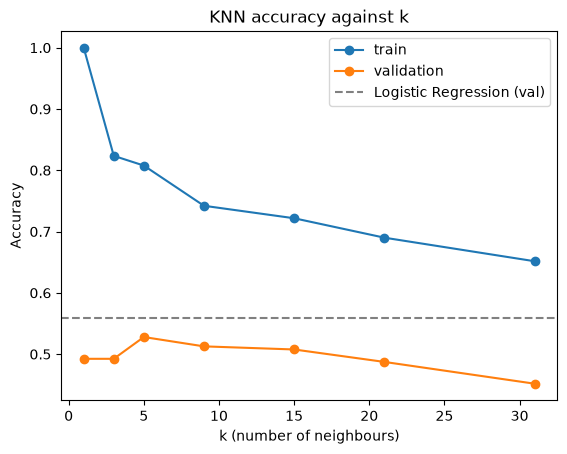

In [8]:
plt.title("KNN accuracy against k")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Accuracy")
plt.plot(k_list, train_accuracies, marker="o", label="train")
plt.plot(k_list, val_accuracies, marker="o", label="validation")

plt.axhline(logreg_accuracy, linestyle="--", color="gray", label="Logistic Regression (val)")
plt.legend()
plt.show()

In [9]:
# kNN on the 9 LDA directions instead of all 145 features
# shrinkage because 442 clips vs 145 features
shrinkage_list = [0.1, 0.3, 0.5, 0.7, 0.9]
weights_list = ["uniform", "distance"]

best_lda_val_accuracy = 0
best_lda_knn = None
best_lda_settings = None

for shrinkage in shrinkage_list:
    for k in k_list:
        for weights in weights_list:

            lda_knn = sklearn.pipeline.make_pipeline(
                sklearn.discriminant_analysis.LinearDiscriminantAnalysis(solver="eigen", shrinkage=shrinkage),
                sklearn.neighbors.KNeighborsClassifier(n_neighbors=k, weights=weights))

            lda_knn.fit(X_train_sc, y_train)

            lda_knn_accuracy = sklearn.metrics.accuracy_score(y_val, lda_knn.predict(X_val_sc))

            if lda_knn_accuracy > best_lda_val_accuracy:

                best_lda_val_accuracy = lda_knn_accuracy
                best_lda_knn = lda_knn
                best_lda_settings = (shrinkage, k, weights)

    print(f"shrinkage up to {shrinkage}: best Val Accuracy so far {best_lda_val_accuracy:.4f}")

best_lda_train_accuracy = sklearn.metrics.accuracy_score(y_train, best_lda_knn.predict(X_train_sc))
print(f"\nbest LDA + KNN: shrinkage = {best_lda_settings[0]}, k = {best_lda_settings[1]}, weights = {best_lda_settings[2]}")
print(f"Val Accuracy: {best_lda_val_accuracy:.4f}  Train Accuracy: {best_lda_train_accuracy:.4f}")

shrinkage up to 0.1: best Val Accuracy so far 0.6142


shrinkage up to 0.3: best Val Accuracy so far 0.6244
shrinkage up to 0.5: best Val Accuracy so far 0.6244
shrinkage up to 0.7: best Val Accuracy so far 0.6497


shrinkage up to 0.9: best Val Accuracy so far 0.6497

best LDA + KNN: shrinkage = 0.7, k = 5, weights = distance
Val Accuracy: 0.6497  Train Accuracy: 1.0000


Logistic Regression                                     Val Accuracy: 0.5584
KNN (k = 5)                                             Val Accuracy: 0.5279
LDA + KNN (shrinkage = 0.7, k = 5, distance)            Val Accuracy: 0.6497

Selected on validation: LDA + KNN (shrinkage = 0.7, k = 5, distance)
Final Accuracy: 0.5862


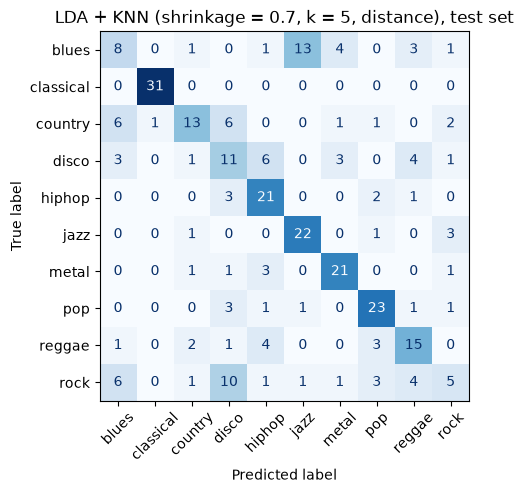

blues      0.26
classical  1.00
country    0.43
disco      0.38
hiphop     0.78
jazz       0.81
metal      0.78
pop        0.77
reggae     0.58
rock       0.16


In [10]:
val_scores = {
    "Logistic Regression": (logreg_accuracy, logreg),
    f"KNN (k = {best_k})": (best_val_accuracy, best_knn),
    f"LDA + KNN (shrinkage = {best_lda_settings[0]}, k = {best_lda_settings[1]}, {best_lda_settings[2]})": (best_lda_val_accuracy, best_lda_knn),
}
for name, (acc, _) in val_scores.items():
    print(f"{name:55s} Val Accuracy: {acc:.4f}")

best_name = max(val_scores, key=lambda name: val_scores[name][0])
best_model = val_scores[best_name][1]
print("\nSelected on validation:", best_name)

# test set, used once
final_predictions = best_model.predict(X_test_sc)
final_accuracy = sklearn.metrics.accuracy_score(y_test, final_predictions)
print(f"Final Accuracy: {final_accuracy:.4f}")

final_confusion_matrix = sklearn.metrics.confusion_matrix(y_test, final_predictions)
sklearn.metrics.ConfusionMatrixDisplay(final_confusion_matrix, display_labels=genre_names).plot(
    cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title(f"{best_name}, test set")
plt.show()

# per-genre recall
for genre, recall in zip(genre_names, final_confusion_matrix.diagonal() / final_confusion_matrix.sum(axis=1)):
    print(f"{genre:10s} {recall:.2f}")

In [11]:
# comparison only, selection is already done
for name, (_, model) in val_scores.items():
    if name != best_name:
        print(f"{name:55s} Test Accuracy: {sklearn.metrics.accuracy_score(y_test, model.predict(X_test_sc)):.4f}")

Logistic Regression                                     Test Accuracy: 0.6103
KNN (k = 5)                                             Test Accuracy: 0.5103


In [12]:
# refit the chosen settings on train + valid (639 clips)
X_train_val = np.concatenate([X_train, X_val])
y_train_val = np.concatenate([y_train, y_val])

scaler_tv = sklearn.preprocessing.StandardScaler().fit(X_train_val)
X_train_val_sc = scaler_tv.transform(X_train_val)
X_test_sc_tv = scaler_tv.transform(X_test)

refit_model = sklearn.base.clone(best_model).fit(X_train_val_sc, y_train_val)

refit_accuracy = sklearn.metrics.accuracy_score(y_test, refit_model.predict(X_test_sc_tv))
print(f"{best_name} refitted on train + val, Test Accuracy: {refit_accuracy:.4f}")

LDA + KNN (shrinkage = 0.7, k = 5, distance) refitted on train + val, Test Accuracy: 0.5793


In [13]:
# handcrafted features cap out near 60%, so try AST embeddings
# from scripts/embed.py: (N, 5 windows, 768)

ast = {split: np.load(DATA / "embeddings" / f"ast_{split}.npz") for split in ["train", "valid", "test"]}

# same clip order as the features
for split, d in ast.items():
    assert list(d["paths"]) == valid_files[split]

# mean over windows, then L2-normalise
E_train = sklearn.preprocessing.normalize(ast["train"]["emb"].mean(axis=1))
E_val = sklearn.preprocessing.normalize(ast["valid"]["emb"].mean(axis=1))
E_test = sklearn.preprocessing.normalize(ast["test"]["emb"].mean(axis=1))
print("embeddings:", E_train.shape, E_val.shape, E_test.shape)

best_emb_k = 0
best_emb_val_accuracy = 0
best_emb_knn = None
for k in k_list:

    emb_knn = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k).fit(E_train, y_train)

    emb_knn_accuracy = sklearn.metrics.accuracy_score(y_val, emb_knn.predict(E_val))
    emb_knn_accuracy_train = sklearn.metrics.accuracy_score(y_train, emb_knn.predict(E_train))
    print(f"k = {k:2d}  Val Accuracy: {emb_knn_accuracy:.4f}  Train Accuracy: {emb_knn_accuracy_train:.4f}")

    # ties go to the larger k
    if emb_knn_accuracy >= best_emb_val_accuracy:
        best_emb_k = k
        best_emb_val_accuracy = emb_knn_accuracy
        best_emb_knn = emb_knn

print(f"\nbest embedding KNN was k equal to {best_emb_k} with Val Accuracy {best_emb_val_accuracy:.4f}")

embeddings: (442, 768) (197, 768) (290, 768)
k =  1  Val Accuracy: 0.7310  Train Accuracy: 1.0000
k =  3  Val Accuracy: 0.7513  Train Accuracy: 0.9321
k =  5  Val Accuracy: 0.7665  Train Accuracy: 0.9118
k =  9  Val Accuracy: 0.7563  Train Accuracy: 0.9005
k = 15  Val Accuracy: 0.7614  Train Accuracy: 0.8733
k = 21  Val Accuracy: 0.7563  Train Accuracy: 0.8529
k = 31  Val Accuracy: 0.7614  Train Accuracy: 0.8213

best embedding KNN was k equal to 5 with Val Accuracy 0.7665


In [14]:
# 768 dims vs 442 clips, so LDA needs shrinkage
best_emb_lda_val_accuracy = 0
best_emb_lda_knn = None
best_emb_lda_settings = None

for shrinkage in shrinkage_list:
    for k in k_list:
        for weights in weights_list:

            emb_lda_knn = sklearn.pipeline.make_pipeline(
                sklearn.discriminant_analysis.LinearDiscriminantAnalysis(solver="eigen", shrinkage=shrinkage),
                sklearn.neighbors.KNeighborsClassifier(n_neighbors=k, weights=weights))
            emb_lda_knn.fit(E_train, y_train)

            emb_lda_knn_accuracy = sklearn.metrics.accuracy_score(y_val, emb_lda_knn.predict(E_val))

            if emb_lda_knn_accuracy > best_emb_lda_val_accuracy:
                best_emb_lda_val_accuracy = emb_lda_knn_accuracy
                best_emb_lda_knn = emb_lda_knn
                best_emb_lda_settings = (shrinkage, k, weights)

print(f"best embedding LDA + KNN: shrinkage = {best_emb_lda_settings[0]}, k = {best_emb_lda_settings[1]}, "
      f"weights = {best_emb_lda_settings[2]}, Val Accuracy: {best_emb_lda_val_accuracy:.4f}")

best embedding LDA + KNN: shrinkage = 0.3, k = 5, weights = uniform, Val Accuracy: 0.8020


AST + KNN (k = 5)                                            Val Accuracy: 0.7665
AST + LDA + KNN (shrinkage = 0.3, k = 5, uniform)            Val Accuracy: 0.8020

Selected on validation: AST + LDA + KNN (shrinkage = 0.3, k = 5, uniform)
Final Accuracy: 0.8552


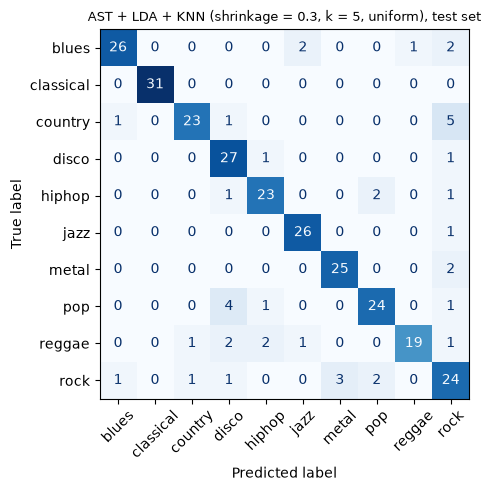

blues      0.84
classical  1.00
country    0.77
disco      0.93
hiphop     0.85
jazz       0.96
metal      0.93
pop        0.80
reggae     0.73
rock       0.75

AST + KNN (k = 5) Test Accuracy: 0.8034


In [15]:
emb_val_scores = {
    f"AST + KNN (k = {best_emb_k})": (best_emb_val_accuracy, best_emb_knn),
    f"AST + LDA + KNN (shrinkage = {best_emb_lda_settings[0]}, k = {best_emb_lda_settings[1]}, {best_emb_lda_settings[2]})":
        (best_emb_lda_val_accuracy, best_emb_lda_knn),
}
for name, (acc, _) in emb_val_scores.items():
    print(f"{name:60s} Val Accuracy: {acc:.4f}")
best_emb_name = max(emb_val_scores, key=lambda name: emb_val_scores[name][0])
best_emb_model = emb_val_scores[best_emb_name][1]
print("\nSelected on validation:", best_emb_name)

# test set, used once
emb_final_predictions = best_emb_model.predict(E_test)
emb_final_accuracy = sklearn.metrics.accuracy_score(y_test, emb_final_predictions)
print(f"Final Accuracy: {emb_final_accuracy:.4f}")

emb_confusion_matrix = sklearn.metrics.confusion_matrix(y_test, emb_final_predictions)
sklearn.metrics.ConfusionMatrixDisplay(emb_confusion_matrix, display_labels=genre_names).plot(
    cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title(f"{best_emb_name}, test set", fontsize=9)
plt.show()

for genre, recall in zip(genre_names, emb_confusion_matrix.diagonal() / emb_confusion_matrix.sum(axis=1)):
    print(f"{genre:10s} {recall:.2f}")

# comparison only, selection is already done
for name, (_, model) in emb_val_scores.items():
    if name != best_emb_name:
        print(f"\n{name} Test Accuracy: {sklearn.metrics.accuracy_score(y_test, model.predict(E_test)):.4f}")

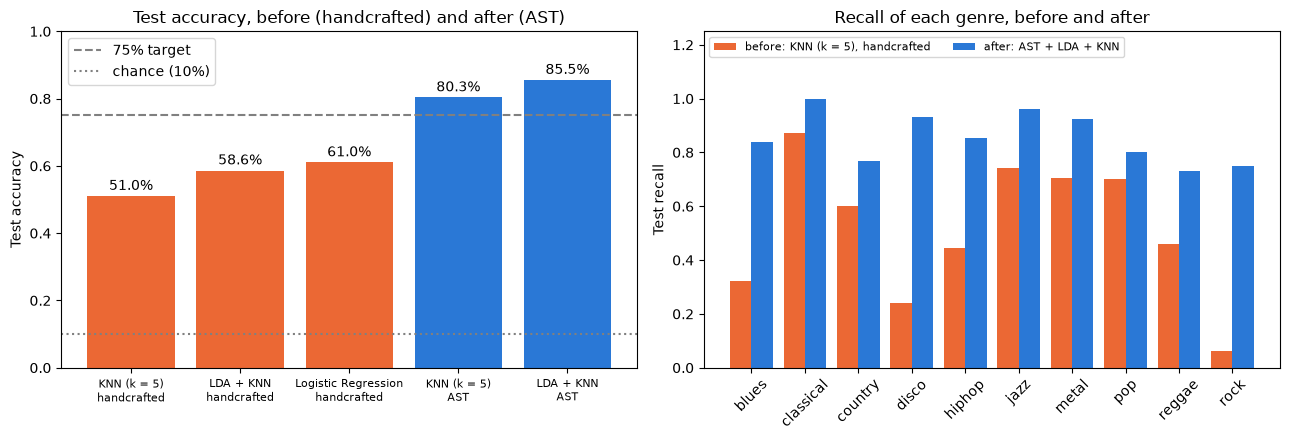

genre       before   after  change
blues         0.32    0.84   +0.52
classical     0.87    1.00   +0.13
country       0.60    0.77   +0.17
disco         0.24    0.93   +0.69
hiphop        0.44    0.85   +0.41
jazz          0.74    0.96   +0.22
metal         0.70    0.93   +0.22
pop           0.70    0.80   +0.10
reggae        0.46    0.73   +0.27
rock          0.06    0.75   +0.69

overall test accuracy: 0.5103 -> 0.8552 (+0.3448)


In [16]:
# before/after: handcrafted kNN vs the final AST model

before_after = {
    f"KNN (k = {best_k})\nhandcrafted": sklearn.metrics.accuracy_score(y_test, best_knn.predict(X_test_sc)),
    "LDA + KNN\nhandcrafted": sklearn.metrics.accuracy_score(y_test, best_lda_knn.predict(X_test_sc)),
    "Logistic Regression\nhandcrafted": sklearn.metrics.accuracy_score(y_test, logreg.predict(X_test_sc)),
    f"KNN (k = {best_emb_k})\nAST": sklearn.metrics.accuracy_score(y_test, best_emb_knn.predict(E_test)),
    "LDA + KNN\nAST": sklearn.metrics.accuracy_score(y_test, best_emb_lda_knn.predict(E_test)),
}

before_cm = sklearn.metrics.confusion_matrix(y_test, best_knn.predict(X_test_sc))
after_cm = sklearn.metrics.confusion_matrix(y_test, best_emb_model.predict(E_test))
before_recall = before_cm.diagonal() / before_cm.sum(axis=1)
after_recall = after_cm.diagonal() / after_cm.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

names_ba = list(before_after)
colors = ["#eb6834" if "handcrafted" in n else "#2a78d6" for n in names_ba]
bars = axes[0].bar(names_ba, [before_after[n] for n in names_ba], color=colors)
axes[0].bar_label(bars, labels=[f"{v:.1%}" for v in before_after.values()], padding=2)
axes[0].axhline(0.75, linestyle="--", color="gray", label="75% target")
axes[0].axhline(0.10, linestyle=":", color="gray", label="chance (10%)")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Test accuracy, before (handcrafted) and after (AST)")
axes[0].tick_params(axis="x", labelsize=8)
axes[0].legend(loc="upper left")

x = np.arange(len(genre_names))
axes[1].bar(x - 0.2, before_recall, width=0.4, color="#eb6834", label=f"before: KNN (k = {best_k}), handcrafted")
axes[1].bar(x + 0.2, after_recall, width=0.4, color="#2a78d6", label=f"after: {best_emb_name.split(' (')[0]}")
axes[1].set_xticks(x, genre_names, rotation=45)
axes[1].set_ylim(0, 1.25)
axes[1].set_ylabel("Test recall")
axes[1].set_title("Recall of each genre, before and after")
axes[1].legend(loc="upper left", ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

print(f"{'genre':10s} {'before':>7s} {'after':>7s} {'change':>7s}")
for genre, b, a in zip(genre_names, before_recall, after_recall):
    print(f"{genre:10s} {b:7.2f} {a:7.2f} {a - b:+7.2f}")
first, last = before_after[names_ba[0]], before_after[names_ba[-1]]
print(f"\noverall test accuracy: {first:.4f} -> {last:.4f} ({last - first:+.4f})")